In [4]:
import os

print("Current folder:", os.getcwd())
print("Processed folder exists:", os.path.exists("../data/processed"))
print("Required file exists:",
      os.path.exists("../data/processed/split_and_preprocessors.joblib"))

Current folder: C:\Users\ACER\Desktop\ProductPricePrediction_final\notebooks
Processed folder exists: True
Required file exists: True


In [5]:
import time
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

RANDOM_STATE = 42

saved = joblib.load("../data/processed/split_and_preprocessors.joblib")

X_train, X_test = saved["X_train"], saved["X_test"]
y_train, y_test = saved["y_train"], saved["y_test"]                    # log scale
y_train_price, y_test_price = saved["y_train_price"], saved["y_test_price"]  # dollars

numeric_features = saved["numeric_features"]
categorical_features = saved["categorical_features"]
sparse_preprocessor = saved["sparse_preprocessor"]
svd_preprocessor = saved["svd_preprocessor"]

print("Train:", X_train.shape, "| Test:", X_test.shape)

Train: (79954, 15) | Test: (19989, 15)


In [6]:
def evaluate_regression(model_name, model, X_train, X_test, y_train_log, y_test_log, y_test_dollars):
    """Models are trained on log1p(price). Predictions are converted back to dollars."""
    start = time.time()
    model.fit(X_train, y_train_log)
    pred_log = np.clip(model.predict(X_test), 0, None)   # price can't be negative
    pred_price = np.expm1(pred_log)

    result = {
        "model": model_name,
        "MAE": mean_absolute_error(y_test_dollars, pred_price),
        "RMSE": mean_squared_error(y_test_dollars, pred_price) ** 0.5,
        "R2": r2_score(y_test_dollars, pred_price),
        "RMSLE": mean_squared_error(y_test_log, pred_log) ** 0.5,
        "R2_log": r2_score(y_test_log, pred_log),
        "training_seconds": time.time() - start
    }
    return result, pred_price

## Evaluation Metrics
- **MAE / RMSE / R²** are calculated in **dollars** (after `expm1`), so they are easy to explain.
- **RMSLE** is the RMSE of `log1p(price)`. It treats a \$5 error on a \$10 item as
  more serious than a \$5 error on a \$200 item, which suits this skewed target.
  It is also the metric of the original Kaggle competition.
- **R2_log** is R² on the log scale.

In [7]:
from sklearn.dummy import DummyRegressor

dummy = DummyRegressor(strategy="mean")
dummy_result, dummy_pred = evaluate_regression(
    "Dummy Regressor (mean)", dummy, X_train, X_test, y_train, y_test, y_test_price
)
print(dummy_result)

{'model': 'Dummy Regressor (mean)', 'MAE': 15.864007587777246, 'RMSE': 36.05571614063055, 'R2': -0.04773196247590983, 'RMSLE': 0.7423782754539406, 'R2_log': -5.382991810298776e-05, 'training_seconds': 0.0790090560913086}


In [8]:
from sklearn.linear_model import LinearRegression, Ridge

linear_pipeline = Pipeline([
    ("preprocessing", clone(sparse_preprocessor)),
    ("model", LinearRegression())
])

linear_result, linear_pred = evaluate_regression(
    "Linear Regression - TF-IDF", linear_pipeline, X_train, X_test, y_train, y_test, y_test_price
)
print(linear_result)

{'model': 'Linear Regression - TF-IDF', 'MAE': 11.69653782135125, 'RMSE': 28.20803794641515, 'R2': 0.35871999442452773, 'RMSLE': 0.5278736838704988, 'R2_log': 0.4943699322411217, 'training_seconds': 39.62951397895813}


In [9]:
ridge_pipeline = Pipeline([
    ("preprocessing", clone(sparse_preprocessor)),
    ("model", Ridge(alpha=3.0, random_state=RANDOM_STATE))
])

ridge_result, ridge_pred = evaluate_regression(
    "Ridge - TF-IDF", ridge_pipeline, X_train, X_test, y_train, y_test, y_test_price
)
print(ridge_result)

{'model': 'Ridge - TF-IDF', 'MAE': 11.474235336183227, 'RMSE': 28.267209447385785, 'R2': 0.35602676922777843, 'RMSLE': 0.5151607279461987, 'R2_log': 0.5184311745522951, 'training_seconds': 15.120090246200562}


In [12]:
from sklearn.ensemble import RandomForestRegressor

rf_pipeline = Pipeline([
    ("preprocessing", clone(svd_preprocessor)),
    ("model", RandomForestRegressor(
        n_estimators=20,
        max_features=0.3,        # each split checks 30% of columns -> much faster
        min_samples_leaf=5,
        random_state=RANDOM_STATE,
        n_jobs=-1
    ))
])

rf_result, rf_pred = evaluate_regression(
    "Random Forest - TF-IDF + SVD", rf_pipeline, X_train, X_test, y_train, y_test, y_test_price
)
print(rf_result)


KeyboardInterrupt



In [13]:
print(rf_result)

{'model': 'Random Forest - TF-IDF + SVD', 'MAE': 13.039839123834087, 'RMSE': 31.700689625319843, 'R2': 0.190085151601308, 'RMSLE': 0.5912518253069868, 'R2_log': 0.3656661935068358, 'training_seconds': 485.20469665527344}


In [14]:
baseline_comparison = pd.DataFrame([
    dummy_result, linear_result, ridge_result, rf_result
])

display(
    baseline_comparison.sort_values("RMSLE", ascending=True).round(4)
)

,model,MAE,RMSE,R2,RMSLE,R2_log,training_seconds
2,Ridge - TF-IDF,11.4742,28.2672,0.3560,0.5152,0.5184,15.1201
1,Linear Regression - TF-IDF,11.6965,28.2080,0.3587,0.5279,0.4944,39.6295
3,Random Forest - TF-IDF + SVD,13.0398,31.7007,0.1901,0.5913,0.3657,485.2047
0,Dummy Regressor (mean),15.8640,36.0557,-0.0477,0.7424,-0.0001,0.0790


## Baseline Model Comparison
- The Dummy Regressor (always predicts the average) gives RMSLE 0.7424 and R² -0.048.
  Every real model must beat this.
- Linear Regression on TF-IDF: RMSLE 0.5279, MAE \$11.70.
- Ridge on TF-IDF: RMSLE 0.5152, MAE \$11.47 (best baseline).
- Random Forest on TF-IDF + SVD: RMSLE 0.5798, MAE \$12.82, and it took about 32
  minutes to train, far slower than the linear models.
- Why Random Forest did worst: TruncatedSVD kept only about 20-29% of the text
  variance, so the forest sees much less text information than Ridge does.
  Trees also struggle with hundreds of sparse one-hot columns.
- R² in dollars (about 0.36) is lower than R² on the log scale (0.52) because a
  few expensive items create very large dollar errors.

In [15]:
from scipy import sparse

svd_fitted = clone(svd_preprocessor).fit(X_train)
X_train_svd = svd_fitted.transform(X_train)
X_test_svd = svd_fitted.transform(X_test)

# make sure the matrices are dense arrays
if sparse.issparse(X_train_svd):
    X_train_svd = X_train_svd.toarray()
    X_test_svd = X_test_svd.toarray()

print(X_train_svd.shape, X_test_svd.shape)

(79954, 735) (19989, 735)


In [16]:
rng = np.random.RandomState(RANDOM_STATE)
tune_idx = rng.choice(len(X_train_svd), size=20_000, replace=False)

X_tune = X_train_svd[tune_idx]
y_tune = y_train.iloc[tune_idx]

print("Tuning subset:", X_tune.shape)

Tuning subset: (20000, 735)


In [17]:
from sklearn.model_selection import cross_val_score

lr_cv = -cross_val_score(
    linear_pipeline, X_train, y_train,
    cv=5, scoring="neg_root_mean_squared_error"
)
print("Linear Regression CV RMSLE:", lr_cv.round(4))
print("Mean:", lr_cv.mean().round(4), "| Std:", lr_cv.std().round(4))


rf_small = RandomForestRegressor(
    n_estimators=50, max_features=0.3, min_samples_leaf=3,
    random_state=RANDOM_STATE, n_jobs=-1
)
rf_cv = -cross_val_score(
    rf_small, X_tune, y_tune,
    cv=3, scoring="neg_root_mean_squared_error"
)
print("Random Forest CV RMSLE:", rf_cv.round(4))
print("Mean:", rf_cv.mean().round(4), "| Std:", rf_cv.std().round(4))

Linear Regression CV RMSLE: [0.5341 0.5418 0.5375 0.535  0.5353]
Mean: 0.5367 | Std: 0.0028
Random Forest CV RMSLE: [0.6217 0.6218 0.6168]
Mean: 0.6201 | Std: 0.0023


In [18]:
from sklearn.model_selection import GridSearchCV

rf_grid = GridSearchCV(
    estimator=RandomForestRegressor(
        n_estimators=50, max_features=0.3,
        random_state=RANDOM_STATE, n_jobs=-1
    ),
    param_grid={
        "max_depth": [10, 20],
        "min_samples_leaf": [2, 5]
    },
    cv=3,
    scoring="neg_root_mean_squared_error",
    verbose=1
)

rf_grid.fit(X_tune, y_tune)

print("Best parameters:", rf_grid.best_params_)
print("Best CV RMSLE:", round(-rf_grid.best_score_, 4))

Fitting 3 folds for each of 4 candidates, totalling 12 fits
Best parameters: {'max_depth': 20, 'min_samples_leaf': 2}
Best CV RMSLE: 0.6192


In [19]:
from sklearn.model_selection import RandomizedSearchCV

rf_random = RandomizedSearchCV(
    estimator=RandomForestRegressor(
        n_estimators=50, random_state=RANDOM_STATE, n_jobs=-1
    ),
    param_distributions={
        "max_depth": [8, 12, 16, 24, None],
        "min_samples_leaf": [1, 3, 5, 10],
        "max_features": [0.2, 0.3, 0.5]
    },
    n_iter=4,
    cv=3,
    scoring="neg_root_mean_squared_error",
    random_state=RANDOM_STATE,
    verbose=1
)

rf_random.fit(X_tune, y_tune)

print("Best parameters:", rf_random.best_params_)
print("Best CV RMSLE:", round(-rf_random.best_score_, 4))

Fitting 3 folds for each of 4 candidates, totalling 12 fits
Best parameters: {'min_samples_leaf': 1, 'max_features': 0.2, 'max_depth': 24}
Best CV RMSLE: 0.62


In [20]:
if -rf_grid.best_score_ <= -rf_random.best_score_:
    best_params = rf_grid.best_params_
    winner = "GridSearchCV"
else:
    best_params = rf_random.best_params_
    winner = "RandomizedSearchCV"

print("Winner:", winner, best_params)

tuned_rf = RandomForestRegressor(
    n_estimators=100,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    **{"max_features": 0.3, **best_params}   # grid search doesn't set max_features, so default to 0.3
)

tuned_rf_result, tuned_rf_pred = evaluate_regression(
    "Random Forest - tuned", tuned_rf,
    X_train_svd, X_test_svd, y_train, y_test, y_test_price
)
print(tuned_rf_result)

Winner: GridSearchCV {'max_depth': 20, 'min_samples_leaf': 2}
{'model': 'Random Forest - tuned', 'MAE': 12.898153148454725, 'RMSE': 31.573328272705044, 'R2': 0.1965799401562014, 'RMSLE': 0.5856754315421989, 'R2_log': 0.37757521070336164, 'training_seconds': 270.0853817462921}


In [21]:
final_comparison = pd.concat(
    [baseline_comparison, pd.DataFrame([tuned_rf_result])],
    ignore_index=True
)
display(final_comparison.sort_values("RMSLE").round(4))
final_comparison.to_csv("../models/model_results.csv", index=False)

,model,MAE,RMSE,R2,RMSLE,R2_log,training_seconds
2,Ridge - TF-IDF,11.4742,28.2672,0.3560,0.5152,0.5184,15.1201
1,Linear Regression - TF-IDF,11.6965,28.2080,0.3587,0.5279,0.4944,39.6295
4,Random Forest - tuned,12.8982,31.5733,0.1966,0.5857,0.3776,270.0854
3,Random Forest - TF-IDF + SVD,13.0398,31.7007,0.1901,0.5913,0.3657,485.2047
0,Dummy Regressor (mean),15.8640,36.0557,-0.0477,0.7424,-0.0001,0.0790


## Cross-Validation and Tuning Summary
- Cross-validation: Linear Regression RMSLE 0.5367 ± 0.0028 (5-fold); Random Forest
  RMSLE 0.6201 ± 0.0023 (3-fold, 20,000-row subset). Low standard deviations show
  both models are stable across folds.
- GridSearchCV (Random Forest): best parameters max_depth=20, min_samples_leaf=2,
  CV RMSLE 0.6192.
- RandomizedSearchCV (Random Forest): best parameters min_samples_leaf=1,
  max_features=0.2, max_depth=24, CV RMSLE 0.62.
- GridSearchCV won by a very small margin and was refitted on the full training data.
- Tuned Random Forest on the full training data: test RMSLE 0.5857, MAE \$12.90,
  compared with RMSLE 0.5798, MAE \$12.82 before tuning. Accuracy did not improve,
  but training time fell from about 32 minutes to 4.5 minutes.
- Conclusion: Random Forest is limited by its input features (SVD keeps only
  about 20-29% of the text variance), not by its hyperparameters. The linear
  models on full TF-IDF are better.
- CV scores come from a 20,000-row subset, so they are not directly comparable with
  test scores from the full 80,000 rows.

**Why a subset:** an un-tuned Random Forest took about 32 minutes on all 80,000
rows, so searches were run on 20,000 rows and the best settings were refitted
on the full training data.

**Limitation:** the SVD features were fitted once on the training set before
cross-validation. SVD is unsupervised and never sees the target, so leakage is
minimal, but a strict pipeline would refit it inside each fold.

In [22]:
from lightgbm import LGBMRegressor

lgbm_pipeline = Pipeline([
    ("preprocessing", clone(sparse_preprocessor)),
    ("model", LGBMRegressor(
        n_estimators=300,
        learning_rate=0.1,
        num_leaves=63,
        colsample_bytree=0.3,
        random_state=RANDOM_STATE,
        n_jobs=-1,
        verbose=-1
    ))
])

lgbm_result, lgbm_pred = evaluate_regression(
    "LightGBM - TF-IDF", lgbm_pipeline, X_train, X_test, y_train, y_test, y_test_price
)
print(lgbm_result)

{'model': 'LightGBM - TF-IDF', 'MAE': 11.33500687401954, 'RMSE': 28.35035035781371, 'R2': 0.3522330266011966, 'RMSLE': 0.5062972478433614, 'R2_log': 0.5348596645046372, 'training_seconds': 71.18859529495239}


In [ ]:
!pip install lightgbm

In [23]:
model_comparison = pd.concat(
    [final_comparison, pd.DataFrame([lgbm_result])],
    ignore_index=True
)

display(model_comparison.sort_values("RMSLE").round(4))
model_comparison.to_csv("../models/model_results.csv", index=False)


,model,MAE,RMSE,R2,RMSLE,R2_log,training_seconds
5,LightGBM - TF-IDF,11.3350,28.3504,0.3522,0.5063,0.5349,71.1886
2,Ridge - TF-IDF,11.4742,28.2672,0.3560,0.5152,0.5184,15.1201
1,Linear Regression - TF-IDF,11.6965,28.2080,0.3587,0.5279,0.4944,39.6295
4,Random Forest - tuned,12.8982,31.5733,0.1966,0.5857,0.3776,270.0854
3,Random Forest - TF-IDF + SVD,13.0398,31.7007,0.1901,0.5913,0.3657,485.2047
0,Dummy Regressor (mean),15.8640,36.0557,-0.0477,0.7424,-0.0001,0.0790


In [24]:
import os
os.makedirs("../models", exist_ok=True)

joblib.dump(lgbm_pipeline, "../models/lgbm_pipeline.joblib")
np.save("../models/lgbm_test_pred.npy", lgbm_pred)
print("Saved final model and test predictions.")

Saved final model and test predictions.


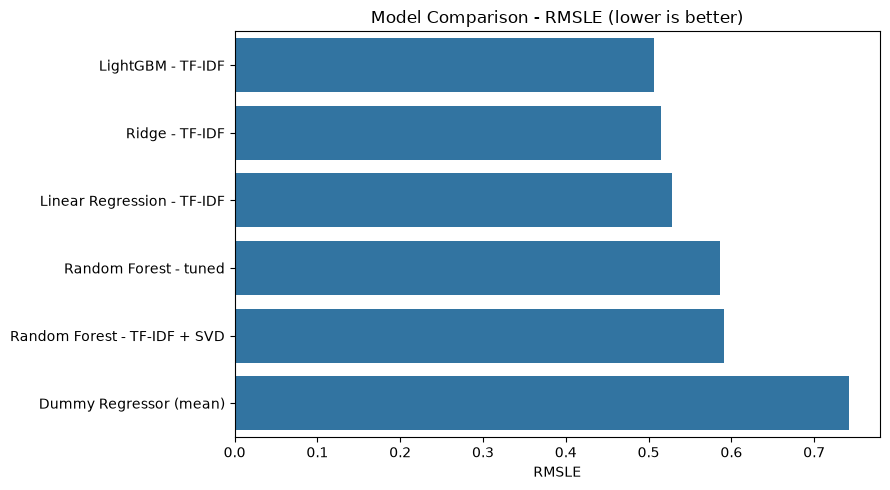

In [25]:
import matplotlib.pyplot as plt
import seaborn as sns

plot_df = model_comparison.sort_values("RMSLE")

plt.figure(figsize=(9, 5))
sns.barplot(data=plot_df, y="model", x="RMSLE")
plt.title("Model Comparison - RMSLE (lower is better)")
plt.xlabel("RMSLE")
plt.ylabel("")
plt.tight_layout()
plt.show()

In [26]:
results_df = pd.DataFrame({
    "name": X_test["name"].values,
    "brand": X_test["brand_name"].values,
    "cat_main": X_test["cat_main"].values,
    "actual": y_test_price.values,
    "predicted": lgbm_pred
})

results_df["residual"] = results_df["actual"] - results_df["predicted"]   # + means under-predicted
results_df["abs_error"] = results_df["residual"].abs()
results_df["log_residual"] = np.log1p(results_df["actual"]) - np.log1p(results_df["predicted"])

results_df.head()

,name,brand,cat_main,actual,predicted,residual,abs_error,log_residual
0,Nike bra,missing,Women,5.0,9.650229,-4.650229,4.650229,-0.573822
1,LOOT CRATE EXCLUSIVE STERLING ARCHER PT2,missing,Men,15.0,19.765937,-4.765937,4.765937,-0.260725
2,NWT VS Pink size M Boyshort/Panty bundle,PINK,Women,26.0,26.503546,-0.503546,0.503546,-0.018478
3,Instantly ageless sachets (20),missing,Beauty,19.0,22.532155,-3.532155,3.532155,-0.162635
4,Ciate London Eyeliner,Sephora,Beauty,10.0,9.297701,0.702299,0.702299,0.065975


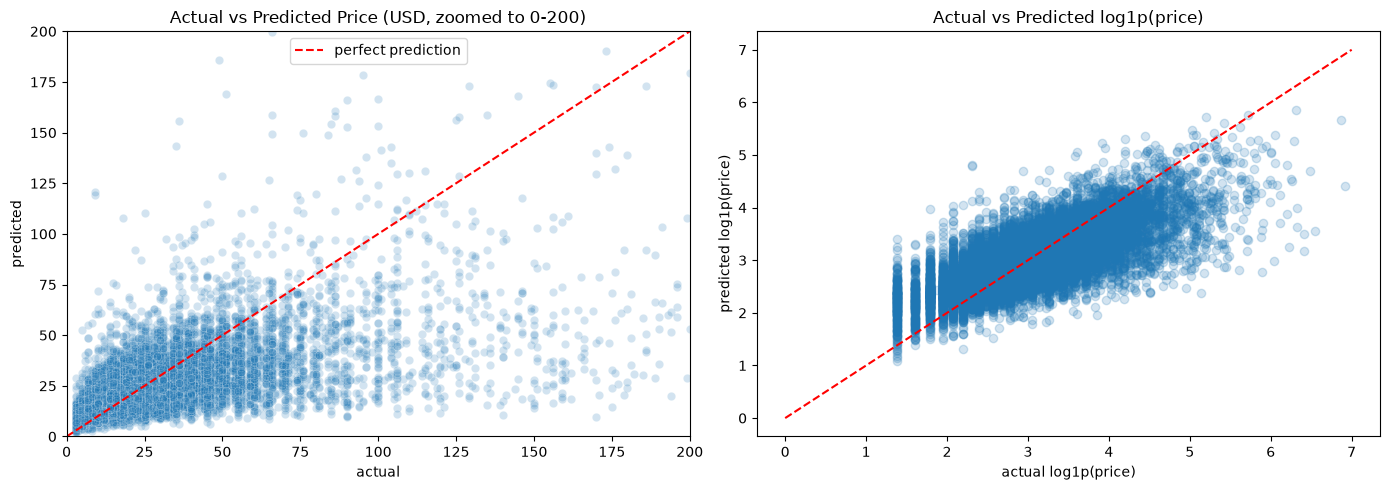

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# dollars (zoomed to 0-200 so the bulk of the data is visible)
sns.scatterplot(data=results_df, x="actual", y="predicted", alpha=0.2, ax=axes[0])
axes[0].plot([0, 200], [0, 200], color="red", linestyle="--", label="perfect prediction")
axes[0].set_xlim(0, 200)
axes[0].set_ylim(0, 200)
axes[0].set_title("Actual vs Predicted Price (USD, zoomed to 0-200)")
axes[0].legend()

# log scale (the scale the model was trained on)
axes[1].scatter(np.log1p(results_df["actual"]), np.log1p(results_df["predicted"]), alpha=0.2)
axes[1].plot([0, 7], [0, 7], color="red", linestyle="--")
axes[1].set_title("Actual vs Predicted log1p(price)")
axes[1].set_xlabel("actual log1p(price)")
axes[1].set_ylabel("predicted log1p(price)")

plt.tight_layout()
plt.show()

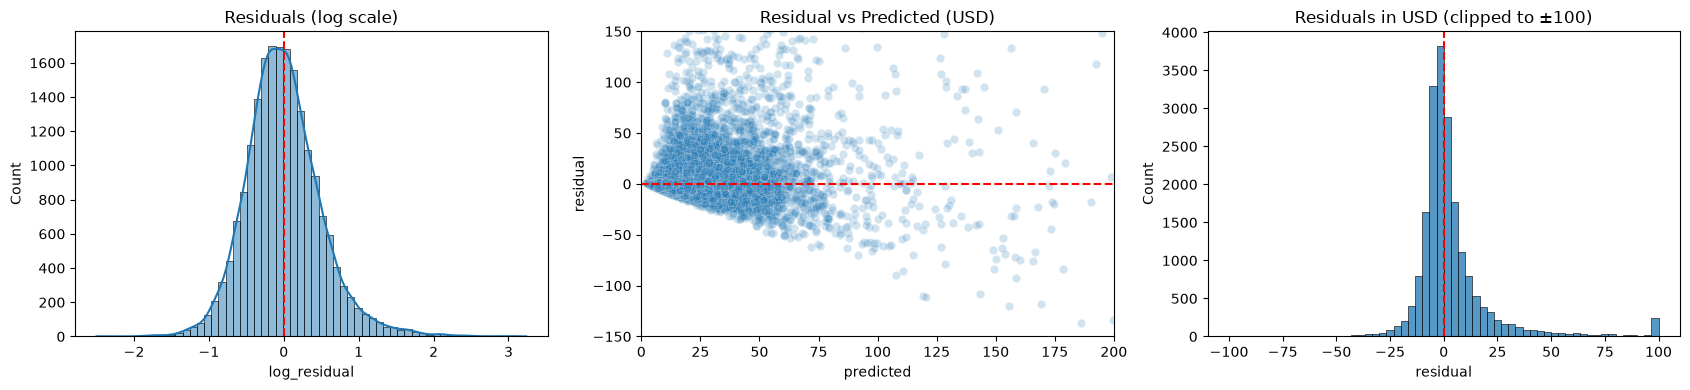

Mean residual (USD): 4.38
Median absolute error (USD): 5.28


In [28]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4))

sns.histplot(results_df["log_residual"], bins=60, kde=True, ax=axes[0])
axes[0].axvline(0, color="red", linestyle="--")
axes[0].set_title("Residuals (log scale)")

sns.scatterplot(data=results_df, x="predicted", y="residual", alpha=0.2, ax=axes[1])
axes[1].axhline(0, color="red", linestyle="--")
axes[1].set_xlim(0, 200)
axes[1].set_ylim(-150, 150)
axes[1].set_title("Residual vs Predicted (USD)")

sns.histplot(results_df["residual"].clip(-100, 100), bins=60, ax=axes[2])
axes[2].axvline(0, color="red", linestyle="--")
axes[2].set_title("Residuals in USD (clipped to ±100)")

plt.tight_layout()
plt.show()

print("Mean residual (USD):", round(results_df["residual"].mean(), 2))
print("Median absolute error (USD):", round(results_df["abs_error"].median(), 2))

In [29]:
results_df["price_range"] = pd.cut(
    results_df["actual"],
    bins=[0, 10, 20, 30, 50, 100, 2000],
    labels=["0-10", "10-20", "20-30", "30-50", "50-100", "100+"]
)

error_by_price = results_df.groupby("price_range", observed=True).agg(
    listings=("actual", "count"),
    MAE=("abs_error", "mean"),
    mean_residual=("residual", "mean")      # negative = over-predicted, positive = under-predicted
).round(2)

display(error_by_price)

,listings,MAE,mean_residual
price_range,,,
0-10,5004,5.04,-4.79
10-20,6998,4.85,-2.30
20-30,3350,7.40,1.88
30-50,2635,13.24,8.36
50-100,1446,30.66,25.98
100+,556,114.13,111.17


In [30]:
error_by_category = results_df.groupby("cat_main").agg(
    listings=("actual", "count"),
    MAE=("abs_error", "mean"),
    mean_residual=("residual", "mean")
).round(2).sort_values("MAE", ascending=False)

display(error_by_category)

,listings,MAE,mean_residual
cat_main,,,
Electronics,1697,18.57,9.54
missing,70,16.85,8.32
Vintage & Collectibles,613,15.09,5.73
Men,1333,14.63,6.38
Sports & Outdoors,316,11.37,4.75
Women,8999,10.97,3.90
Home,914,10.67,3.13
Handmade,423,9.80,4.66
Other,595,9.49,2.91


In [31]:
display(results_df.sort_values("abs_error", ascending=False)
        [["name", "brand", "cat_main", "actual", "predicted", "abs_error"]]
        .head(10).round(2))

,name,brand,cat_main,actual,predicted,abs_error
15853,"Tiffany wedding band originally [rm],000",Tiffany & Co.,Women,1004.0,81.11,922.89
19215,Apple MacBook Pro Early 2015 Retina,Apple,Electronics,955.0,287.55,667.45
18356,WholeSale Bundle,missing,Men,700.0,33.71,666.29
18036,Hold for TM_MR,missing,Electronics,609.0,22.98,586.02
12301,Google pixel xl 32gb,missing,Electronics,604.0,31.77,572.23
15290,2015 speedy 30,Louis Vuitton,Vintage & Collectibles,656.0,109.42,546.58
12828,Genuine Crocodile Handbag,missing,Vintage & Collectibles,556.0,36.72,519.28
14587,Canon t6i,Canon,Electronics,559.0,52.98,506.02
19932,Coach hologram,missing,Women,506.0,24.74,481.26
19802,Set,missing,Women,490.0,47.12,442.88


## Final Model: LightGBM - Error Analysis
- **Actual vs predicted:** on the log scale the points follow the red line but with a
  clear spread. In dollars, items above about \$75 are mostly predicted too low
  (most points sit below the red line).
- **Residuals:** the log-scale residuals are bell-shaped and centred near 0, which
  supports training on `log1p(price)`. In dollars the median absolute error is
  \$5.28, and the mean residual is +\$4.38 (the model under-predicts on average
  because of a small number of very expensive items).
- **By price range:**
  - Items under \$20 have a MAE of about \$5 and are slightly **over-predicted**
    (mean residual -\$4.79 for \$0-10).
  - MAE rises quickly with price: \$7.40 (\$20-30), \$13.24 (\$30-50), \$30.66 (\$50-100).
  - The 556 listings above \$100 have a MAE of \$114.13 and a mean residual of
    +\$111.17, so they are **under-predicted** by about \$111 on average.
  - The model pulls predictions toward the typical price (regression to the middle).
- **By category:** the highest MAE is Electronics (\$18.57), then Vintage &
  Collectibles (\$15.09) and Men (\$14.63). The lowest is Beauty (\$8.10), followed by
  Kids (\$9.22) and Other (\$9.49). Categories with a wide price range are harder.
- **Largest errors:** all top-10 errors are expensive items predicted at \$23-\$290:
  a Tiffany wedding band (actual \$1,004, predicted \$81, title contains Mercari's
  hidden-price "[rm]" tag), a MacBook Pro (\$955 vs \$288), a Google Pixel XL (\$604 vs \$32),
  and listings with uninformative titles such as "WholeSale Bundle" and
  "Hold for TM_MR".
- **Why this happens:** the model minimises error on the log scale, so it plays
  safe and predicts toward the typical price. Expensive items are rare, and
  their titles often give no hint of the high price.
- **Metric note:** this is why RMSLE (0.5063) looks fine while R² in dollars is only
  0.35. A few very large dollar errors dominate R².

In [32]:
import shap
import matplotlib.pyplot as plt

fitted_preprocessor = lgbm_pipeline.named_steps["preprocessing"]
lgbm_model = lgbm_pipeline.named_steps["model"]

feature_names = fitted_preprocessor.get_feature_names_out()

# 1,000 random test rows, transformed and made dense for SHAP
X_explain_raw = X_test.sample(n=1000, random_state=RANDOM_STATE)
X_explain = fitted_preprocessor.transform(X_explain_raw)
if hasattr(X_explain, "toarray"):
    X_explain = X_explain.toarray()

print("Explained matrix:", X_explain.shape, "| feature names:", len(feature_names))

Explained matrix: (1000, 8585) | feature names: 8585


In [33]:
explainer = shap.TreeExplainer(lgbm_model)
shap_values = explainer.shap_values(X_explain)

print("SHAP matrix shape:", shap_values.shape)

SHAP matrix shape: (1000, 8585)


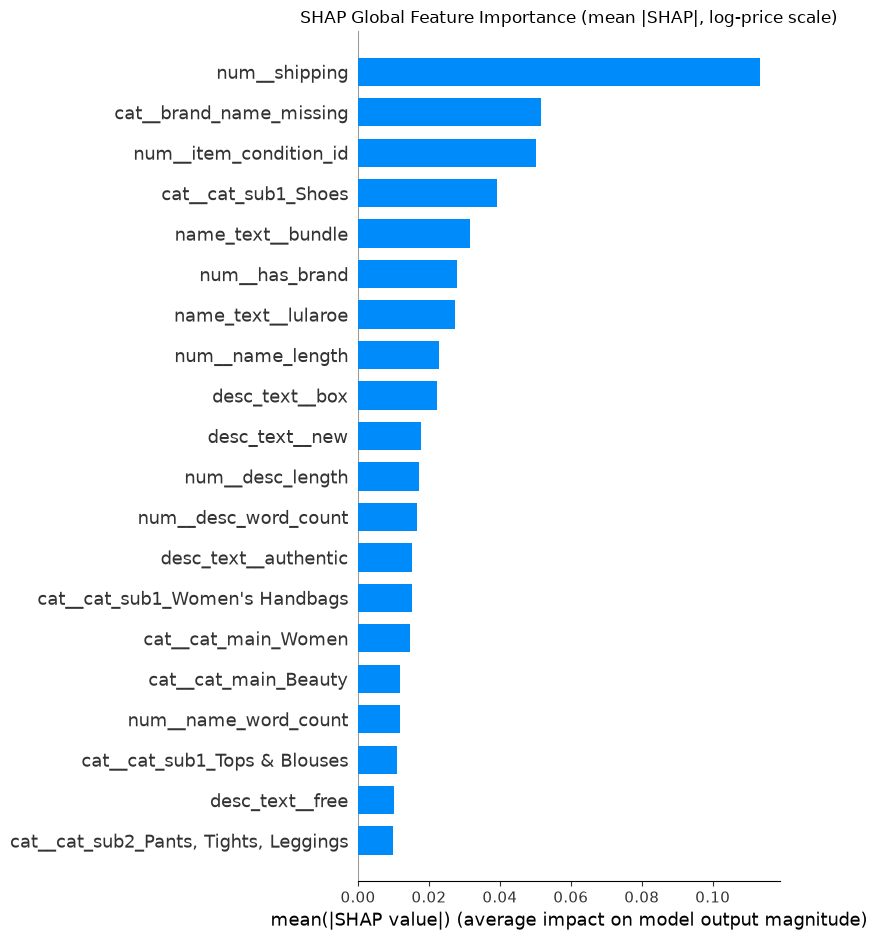

In [34]:
plt.figure()
shap.summary_plot(
    shap_values, X_explain,
    feature_names=feature_names,
    plot_type="bar",
    max_display=20,
    show=False
)
plt.title("SHAP Global Feature Importance (mean |SHAP|, log-price scale)")
plt.tight_layout()
plt.show()

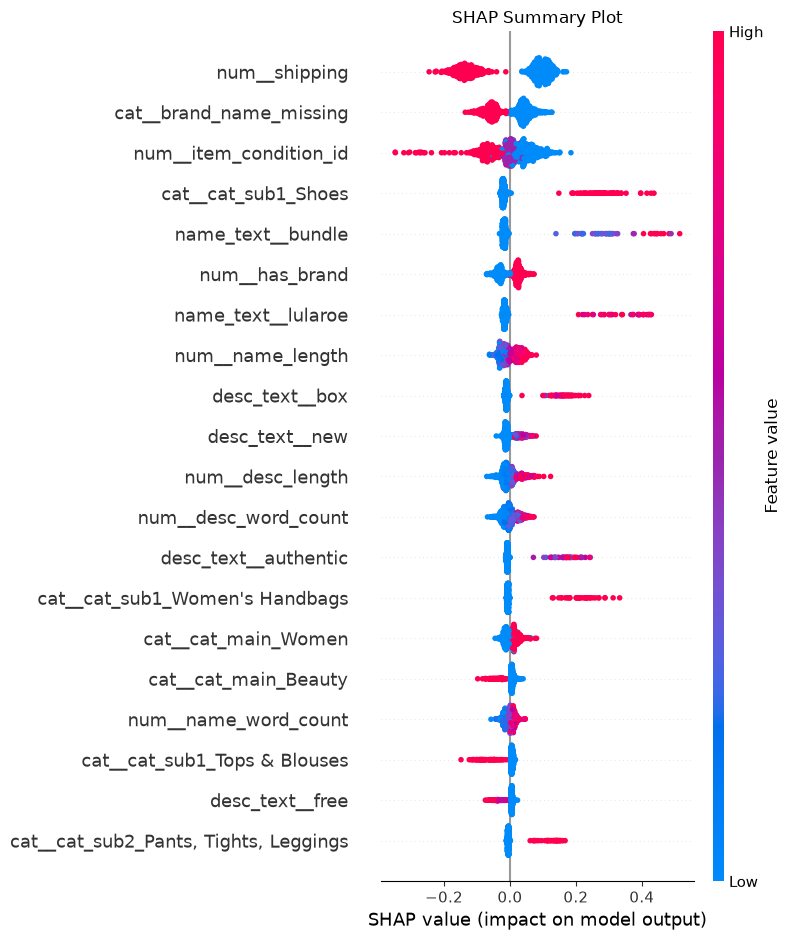

In [35]:
plt.figure()
shap.summary_plot(
    shap_values, X_explain,
    feature_names=feature_names,
    max_display=20,
    show=False
)
plt.title("SHAP Summary Plot")
plt.tight_layout()
plt.show()

In [36]:
importance = pd.DataFrame({
    "feature": feature_names,
    "mean_abs_shap": np.abs(shap_values).mean(axis=0)
})

def feature_group(name):
    if name.startswith("num__"):       return "numeric features"
    if name.startswith("cat__brand"):  return "brand"
    if name.startswith("cat__cat_"):   return "category"
    if name.startswith("name_text__"): return "name text"
    if name.startswith("desc_text__"): return "description text"
    return "other"

importance["group"] = importance["feature"].apply(feature_group)

group_importance = (importance.groupby("group")["mean_abs_shap"]
                    .sum().sort_values(ascending=False).round(4))
display(group_importance.to_frame("total mean |SHAP|"))

display(importance.sort_values("mean_abs_shap", ascending=False).head(15).round(4))

,total mean |SHAP|
group,
description text,0.4598
name text,0.3390
category,0.3147
numeric features,0.2626
brand,0.1394


,feature,mean_abs_shap,group
1,num__shipping,0.1133,numeric features
213,cat__brand_name_missing,0.0516,brand
0,num__item_condition_id,0.0502,numeric features
294,cat__cat_sub1_Shoes,0.0392,category
1063,name_text__bundle,0.0315,name text
8,num__has_brand,0.0278,numeric features
2125,name_text__lularoe,0.0274,name text
2,num__name_length,0.0228,numeric features
4193,desc_text__box,0.0221,description text
6403,desc_text__new,0.0177,description text


Name: Armani Code Body Lotion 2.5 Oz
Brand: missing | Category: Beauty / Skin Care
Condition: 2 | Shipping: 1
Actual price: 10.0
Predicted price: 15.39


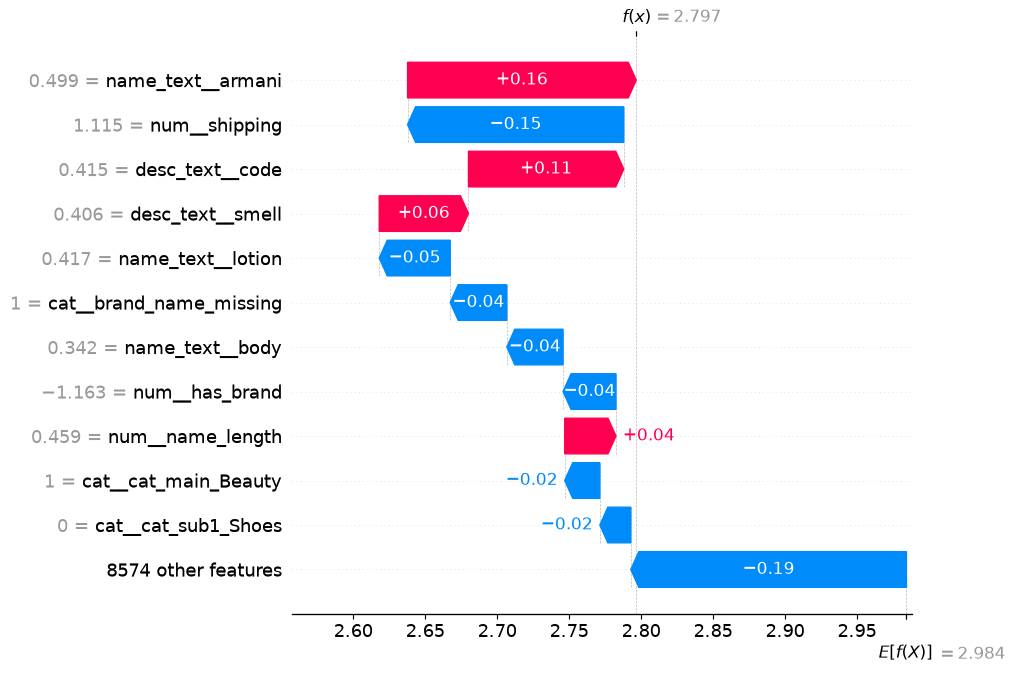

In [37]:
i = 0   # change this number to explain a different listing
listing = X_explain_raw.iloc[i]

print("Name:", listing["name"])
print("Brand:", listing["brand_name"], "| Category:", listing["cat_main"], "/", listing["cat_sub1"])
print("Condition:", listing["item_condition_id"], "| Shipping:", listing["shipping"])
print("Actual price:", round(y_test_price.loc[X_explain_raw.index[i]], 2))

base = explainer.expected_value
base = float(np.ravel(base)[0])
pred_log = base + shap_values[i].sum()
print("Predicted price:", round(np.expm1(pred_log), 2))

shap.plots.waterfall(
    shap.Explanation(
        values=shap_values[i],
        base_values=base,
        data=X_explain[i],
        feature_names=list(feature_names)
    ),
    max_display=12
)

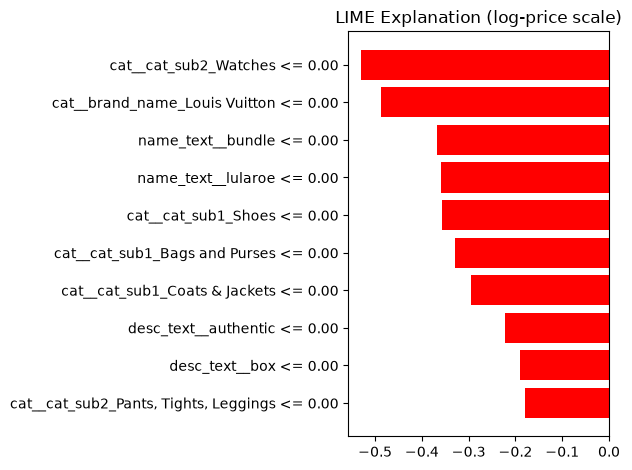

cat__cat_sub2_Watches <= 0.00                           -0.5304
cat__brand_name_Louis Vuitton <= 0.00                   -0.4882
name_text__bundle <= 0.00                               -0.3668
name_text__lularoe <= 0.00                              -0.3601
cat__cat_sub1_Shoes <= 0.00                             -0.3568
cat__cat_sub1_Bags and Purses <= 0.00                   -0.3289
cat__cat_sub1_Coats & Jackets <= 0.00                   -0.2943
desc_text__authentic <= 0.00                            -0.2215
desc_text__box <= 0.00                                  -0.1908
cat__cat_sub2_Pants, Tights, Leggings <= 0.00           -0.1802


In [38]:
from lime.lime_tabular import LimeTabularExplainer

# training data for LIME: a 2,000-row sample of the transformed training set
X_lime_train = fitted_preprocessor.transform(X_train.sample(n=2000, random_state=RANDOM_STATE))
if hasattr(X_lime_train, "toarray"):
    X_lime_train = X_lime_train.toarray()

lime_explainer = LimeTabularExplainer(
    training_data=X_lime_train,
    feature_names=list(feature_names),
    mode="regression",
    random_state=RANDOM_STATE
)

lime_exp = lime_explainer.explain_instance(
    X_explain[i],
    lgbm_model.predict,
    num_features=10,
    num_samples=1000
)

lime_exp.as_pyplot_figure()
plt.title("LIME Explanation (log-price scale)")
plt.tight_layout()
plt.show()

for feature, weight in lime_exp.as_list():
    print(f"{feature:55s} {weight:+.4f}")

## Explainability Results

**SHAP global importance**
- The most important single features are `shipping` (mean |SHAP| 0.113), brand
  missing (0.052), item condition (0.050), sub-category Shoes (0.039), the name word
  "bundle" (0.032) and `has_brand` (0.028).
- By group, description text (0.460) and name text (0.339) have the largest total
  importance, followed by category (0.315), numeric features (0.263) and brand
  (0.139). Text totals are large because they contain thousands of columns, while
  `shipping` is the strongest individual feature.
- From the beeswarm plot: seller-paid shipping lowers the predicted price; having a
  brand raises it and a missing brand lowers it; worse item condition lowers it;
  longer descriptions raise it. Words such as "bundle", "lularoe", "box" and
  "authentic" and the categories Shoes, Women's Handbags and Pants/Tights/Leggings
  raise the price, while Beauty, Tops & Blouses and the word "free" lower it.

**SHAP local explanation (Armani Code Body Lotion 2.5 Oz)**
- Actual price \$10, predicted price \$15.39 (log-scale prediction 2.797).
- The prediction was pushed up by the name word "armani" (+0.16), the description
  words "code" (+0.11) and "smell" (+0.06), and pushed down by seller-paid shipping
  (-0.15), the name word "lotion" (-0.05) and the missing brand (-0.04).
- The model over-predicted by about \$5 because the Armani name suggests a premium product.

**LIME explanation (same listing)**
- LIME's top features were the absence of the Watches sub-category (-0.53), Louis Vuitton
  (-0.49), the words "bundle" (-0.37), "lularoe" (-0.36), "authentic" (-0.22), "box" (-0.19), and the
  Shoes, Bags and Purses and Coats & Jackets sub-categories.
- Agreement with SHAP: both rely on the same group of features (Shoes, "bundle",
  "lularoe", "authentic", "box"). SHAP shows which features present in the listing moved
  the price, while LIME shows that the lack of luxury categories and price-raising
  words keeps this listing's prediction low. LIME is a local approximation built from random
  perturbations of sparse data, so its weights are less stable than SHAP's.

**Business meaning:** price depends mainly on how the seller sets up the listing
(shipping, brand present, condition), the product type (shoes, handbags) and a few
signal words ("bundle", "authentic", "box"), while listing length matters less.

In [39]:
import sys
print(sys.executable)

C:\Users\ACER\AppData\Local\Programs\Python\Python314\python.exe


In [40]:
def create_features(df):
    df = df.copy()

    df["name"] = df["name"].fillna("").astype(str)
    df["item_description"] = df["item_description"].fillna("").astype(str)
    df["brand_name"] = df["brand_name"].fillna("missing")
    df["category_name"] = df["category_name"].fillna("missing/missing/missing")

    df["name_length"] = df["name"].str.len()
    df["name_word_count"] = df["name"].str.split().str.len()
    df["desc_length"] = df["item_description"].str.len()
    df["desc_word_count"] = df["item_description"].str.split().str.len()

    df["no_description"] = (
        (df["item_description"] == "") |
        (df["item_description"] == "No description yet")
    ).astype(int)
    df["rm_count"] = df["item_description"].str.count(r"\[rm\]")

    df["has_brand"] = (df["brand_name"] != "missing").astype(int)

    cats = df["category_name"].str.split("/", n=2, expand=True)
    df["cat_main"] = cats[0].fillna("missing")
    df["cat_sub1"] = cats[1].fillna("missing")
    df["cat_sub2"] = cats[2].fillna("missing")

    return df

In [41]:
import json, datetime, sklearn, lightgbm

MODEL_VERSION = "v1"

joblib.dump(lgbm_pipeline, f"../models/price_model_{MODEL_VERSION}.joblib")

metadata = {
    "model_version": MODEL_VERSION,
    "model": "LightGBM on sparse TF-IDF (name + description) + brand + category + numeric",
    "target": "log1p(price); predictions converted back to USD with expm1",
    "trained_on": str(datetime.date.today()),
    "train_rows": int(len(X_train)),
    "random_state": RANDOM_STATE,
    "test_metrics": {k: round(float(lgbm_result[k]), 4)
                     for k in ["MAE", "RMSE", "R2", "RMSLE", "R2_log"]},
    "library_versions": {
        "scikit-learn": sklearn.__version__,
        "lightgbm": lightgbm.__version__,
        "pandas": pd.__version__,
        "numpy": np.__version__
    }
}

with open(f"../models/price_model_{MODEL_VERSION}_metadata.json", "w") as f:
    json.dump(metadata, f, indent=2)

print(json.dumps(metadata, indent=2))

{
  "model_version": "v1",
  "model": "LightGBM on sparse TF-IDF (name + description) + brand + category + numeric",
  "target": "log1p(price); predictions converted back to USD with expm1",
  "trained_on": "2026-10-20",
  "train_rows": 79954,
  "random_state": 42,
  "test_metrics": {
    "MAE": 11.335,
    "RMSE": 28.3504,
    "R2": 0.3522,
    "RMSLE": 0.5063,
    "R2_log": 0.5349
  },
  "library_versions": {
    "scikit-learn": "1.9.1",
    "lightgbm": "4.7.0",
    "pandas": "3.0.6",
    "numpy": "2.5.3"
  }
}


In [42]:
loaded_model = joblib.load(f"../models/price_model_{MODEL_VERSION}.joblib")

reloaded_pred = np.expm1(np.clip(loaded_model.predict(X_test), 0, None))
print("Predictions identical to the original model:", np.allclose(reloaded_pred, lgbm_pred))

Predictions identical to the original model: True


In [43]:
def predict_price(listings_raw, model=loaded_model):
    """listings_raw: DataFrame with the raw listing columns.
    Returns the estimated selling price in USD."""
    df = listings_raw.copy()
    df["brand_name"] = df["brand_name"].replace(r"^\s*$", np.nan, regex=True)
    df["item_description"] = df["item_description"].replace(r"^\s*$", np.nan, regex=True)

    features = create_features(df)
    pred_log = np.clip(model.predict(features), 0, None)
    return np.round(np.expm1(pred_log), 2)


new_listing = pd.DataFrame([{
    "name": "Nike Air Max running shoes size 9",
    "item_condition_id": 2,
    "category_name": "Women/Shoes/Athletic",
    "brand_name": "Nike",
    "shipping": 0,
    "item_description": "Worn twice, very comfortable, comes with the original box."
}])

print("Estimated price: $", predict_price(new_listing)[0])

Estimated price: $ 42.45


In [44]:
sample_listings = pd.DataFrame([
    {"name": "Nike Air Max running shoes size 9", "item_condition_id": 2,
     "category_name": "Women/Shoes/Athletic", "brand_name": "Nike", "shipping": 0,
     "item_description": "Worn twice, very comfortable, comes with the original box."},
    {"name": "iPhone 8 64GB unlocked", "item_condition_id": 3,
     "category_name": "Electronics/Cell Phones & Accessories/Cell Phones & Smartphones",
     "brand_name": "Apple", "shipping": 1,
     "item_description": "Works perfectly, small scratch on the back."},
    {"name": "Lipstick bundle", "item_condition_id": 1,
     "category_name": "Beauty/Makeup/Lips", "brand_name": "", "shipping": 1,
     "item_description": ""},
    {"name": "Michael Kors handbag authentic", "item_condition_id": 2,
     "category_name": "Women/Women's Handbags/Shoulder Bag", "brand_name": "Michael Kors",
     "shipping": 0, "item_description": "Authentic, dust bag included."},
    {"name": "Baby onesie 3 pack", "item_condition_id": 1,
     "category_name": "Kids/Girls 0-24 Mos/One-Pieces", "brand_name": "",
     "shipping": 1, "item_description": "Brand new, never worn."},
])

sample_listings.to_csv("../data/sample_new_listings.csv", index=False)

# batch inference: read the CSV, predict, save the results
batch = pd.read_csv("../data/sample_new_listings.csv")
batch["predicted_price_usd"] = predict_price(batch)
batch.to_csv("../data/predictions.csv", index=False)

display(batch[["name", "category_name", "brand_name", "shipping", "predicted_price_usd"]])

,name,category_name,brand_name,shipping,predicted_price_usd
0,Nike Air Max running shoes size 9,Women/Shoes/Athletic,Nike,0,42.45
1,iPhone 8 64GB unlocked,Electronics/Cell Phones & Accessories/Cell Pho...,Apple,1,89.82
2,Lipstick bundle,Beauty/Makeup/Lips,NaN,1,13.31
3,Michael Kors handbag authentic,Women/Women's Handbags/Shoulder Bag,Michael Kors,0,71.62
4,Baby onesie 3 pack,Kids/Girls 0-24 Mos/One-Pieces,NaN,1,9.76


In [45]:
import os
import joblib
import pandas as pd

# load the saved training data from Notebook 02
saved = joblib.load("../data/processed/split_and_preprocessors.joblib")
X_train = saved["X_train"]

os.makedirs("../models", exist_ok=True)

# categories that exist in the training data
category_options = (
    X_train[["cat_main", "cat_sub1", "cat_sub2"]]
    .query("cat_main != 'missing'")
    .drop_duplicates()
    .sort_values(["cat_main", "cat_sub1", "cat_sub2"])
)
category_options.to_csv("../models/category_options.csv", index=False)

# brands seen at least 30 times, most common first
brand_counts = X_train["brand_name"].value_counts()
brand_options = brand_counts[(brand_counts >= 30) & (brand_counts.index != "missing")]
pd.DataFrame({"brand_name": brand_options.index}).to_csv("../models/brand_options.csv", index=False)

print(len(category_options), "category rows;", len(brand_options), "brands")

947 category rows; 207 brands
